# Difficulty binning

Pictures of the difficulty groups that each training condition balances:

1. **length**: 4 bins of source length (M2M-100 subword tokens),
2. **loss**: "hard" pairs = per-token loss of the pretrained M2M-100 between the 90th and 99th percentile of ALMA train,
3. **joint**: length × vocabulary rarity, 8 cells (same figure as `data/features/bins_heatmap.png`).

Bin edges come from `scripts/data_utils.py`, so they are exactly the ones used in training.
Figures are also saved to `figures/` for the slides.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Paths are relative to the repository root.
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "scripts")
from data_utils import (LENGTH_EDGES, LENGTH_LABELS, LOSS_HARD_MAX, LOSS_HARD_MIN,
                        RARITY_EDGES, RARITY_LABELS, assign_bins)

FEAT_DIR = Path("data/features")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

SPLITS = {"alma_train": "ALMA train", "wmt22_test": "WMT22", "tatoeba_test": "Tatoeba"}
data = {name: assign_bins(pd.read_csv(FEAT_DIR / f"{split}.csv")) for split, name in SPLITS.items()}
train = data["ALMA train"].merge(pd.read_csv(FEAT_DIR / "alma_train_loss.csv", usecols=["id", "loss_mean"]),
                                 on="id", validate="one_to_one")
assert len(train) == len(data["ALMA train"])

# One shade per bin, light = easy, dark = hard.
LENGTH_COLOUR = dict(zip(LENGTH_LABELS, plt.cm.Blues([0.3, 0.5, 0.7, 0.9])))
LENGTH_TICKS = [f"{l}\n(≤{e})" if e else f"{l}\n(>{LENGTH_EDGES[-1]})"
                for l, e in zip(LENGTH_LABELS, LENGTH_EDGES + [None])]
for name, df in data.items():
    print(f"{name}: {len(df)} sentences")

ALMA train: 15362 sentences
WMT22: 1875 sentences
Tatoeba: 469 sentences


## 1. Length bins

Left: distribution of source length in ALMA train, coloured by bin (x-axis cut at 128 tokens; the few
longer sentences are in "long"). Right: share of each split per bin. The length condition samples
every bin equally often (up to a cap), so it shows short and long sentences more often than uniform sampling.

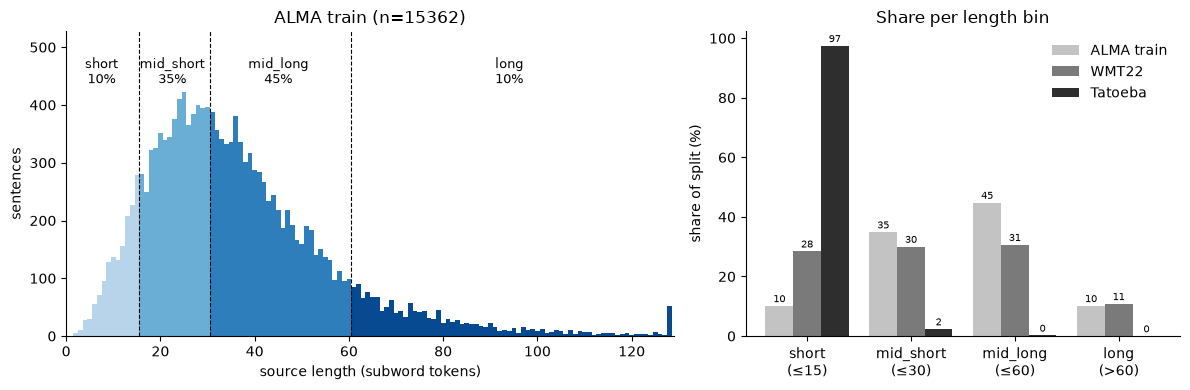

In [2]:
fig, (ax_hist, ax_bar) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.4, 1]})

# Left: histogram, one bar per token count, coloured by bin.
counts = train["src_len"].clip(upper=128).value_counts().sort_index()
bin_of = pd.cut(counts.index, [0, *LENGTH_EDGES, float("inf")], labels=LENGTH_LABELS)
ax_hist.bar(counts.index, counts.values, width=1.0, color=[LENGTH_COLOUR[b] for b in bin_of])
shares = train["length_bin"].value_counts(normalize=True) * 100
lefts = [0, *LENGTH_EDGES]
rights = [*LENGTH_EDGES, 128]
for label, lo, hi in zip(LENGTH_LABELS, lefts, rights):
    ax_hist.text((lo + hi) / 2, counts.max() * 1.02, f"{label}\n{shares[label]:.0f}%",
                 ha="center", va="bottom", fontsize=9)
for edge in LENGTH_EDGES:
    ax_hist.axvline(edge + 0.5, color="black", linewidth=0.8, linestyle="--")
ax_hist.set_ylim(0, counts.max() * 1.25)
ax_hist.set_xlim(0, 129)
ax_hist.set_xlabel("source length (subword tokens)")
ax_hist.set_ylabel("sentences")
ax_hist.set_title(f"ALMA train (n={len(train)})")

# Right: share per bin for each split.
names = list(data)
width = 0.8 / len(names)
for k, name in enumerate(names):
    s = data[name]["length_bin"].value_counts(normalize=True).reindex(LENGTH_LABELS, fill_value=0) * 100
    xs = [i + (k - (len(names) - 1) / 2) * width for i in range(len(LENGTH_LABELS))]
    bars = ax_bar.bar(xs, s.values, width=width, color=plt.cm.Greys(0.35 + 0.25 * k), label=name)
    ax_bar.bar_label(bars, fmt="%.0f", fontsize=7, padding=1)
ax_bar.set_xticks(range(len(LENGTH_LABELS)), LENGTH_TICKS)
ax_bar.set_ylabel("share of split (%)")
ax_bar.set_title("Share per length bin")
ax_bar.legend(frameon=False)

for ax in (ax_hist, ax_bar):
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "bins_length.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Loss bins

Per-token loss of the pretrained M2M-100 on each ALMA training pair (only computed for training data:
it needs the reference, and test data is never used to build the curriculum). The loss condition
balances two groups: **hard** (between the 90th and 99th percentile) and **other**. The top 1% stays
in "other" because it is mostly misaligned pairs, which should not be upsampled.

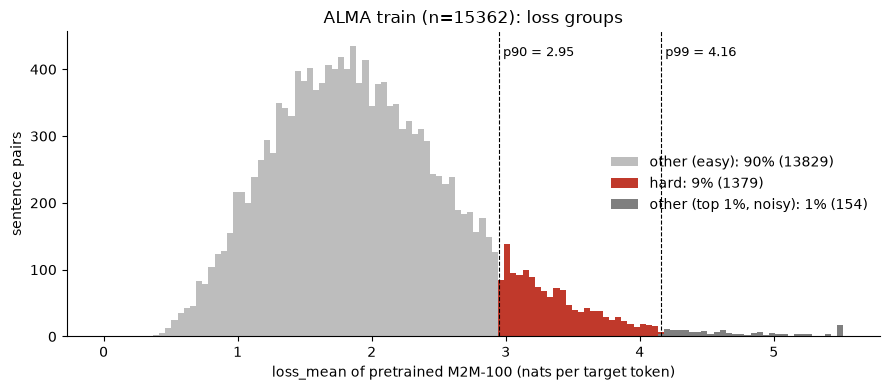

x-axis cut at the 99.9th percentile (5.52); 16 pairs beyond it are drawn in the last bar


In [3]:
loss = train["loss_mean"]
hard = (loss > LOSS_HARD_MIN) & (loss <= LOSS_HARD_MAX)
groups = {
    "other (easy)": loss <= LOSS_HARD_MIN,
    "hard": hard,
    "other (top 1%, noisy)": loss > LOSS_HARD_MAX,
}
colour = {"other (easy)": "#bdbdbd", "hard": "#c0392b", "other (top 1%, noisy)": "#7f7f7f"}

x_max = loss.quantile(0.999)
fig, ax = plt.subplots(figsize=(9, 4))
bins = [i * x_max / 120 for i in range(121)]
for name, mask in groups.items():
    ax.hist(loss[mask].clip(upper=x_max), bins=bins, color=colour[name],
            label=f"{name}: {mask.mean() * 100:.0f}% ({mask.sum()})")
for edge, text in [(LOSS_HARD_MIN, f"p90 = {LOSS_HARD_MIN}"), (LOSS_HARD_MAX, f"p99 = {LOSS_HARD_MAX}")]:
    ax.axvline(edge, color="black", linewidth=0.8, linestyle="--")
    ax.text(edge, ax.get_ylim()[1] * 0.95, f" {text}", fontsize=9, va="top")
ax.set_xlabel("loss_mean of pretrained M2M-100 (nats per target token)")
ax.set_ylabel("sentence pairs")
ax.set_title(f"ALMA train (n={len(train)}): loss groups")
ax.legend(frameon=False, loc="center right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "bins_loss.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"x-axis cut at the 99.9th percentile ({x_max:.2f}); {(loss > x_max).sum()} pairs beyond it are drawn in the last bar")

## 3. Joint bins (length × rarity)

Same as `data/features/bins_heatmap.png` (made by `scripts/make_bins.py`): share of sentences per cell.
Rarity = mean −log p per source subword; typical ≤ 7.9 < rare.

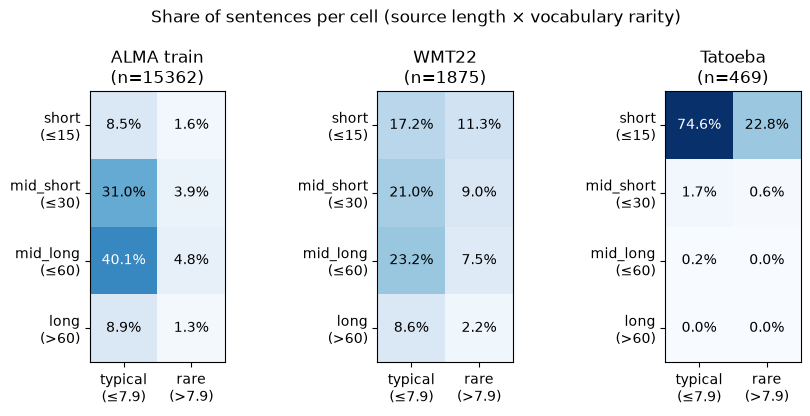

In [4]:
fig, axes = plt.subplots(1, len(data), figsize=(3 * len(data), 4.2))
for ax, (name, df) in zip(axes, data.items()):
    grid = (pd.crosstab(df["length_bin"], df["rarity_bin"], normalize=True)
            .reindex(index=LENGTH_LABELS, columns=RARITY_LABELS, fill_value=0) * 100)
    ax.imshow(grid.values, cmap="Blues", vmin=0, vmax=60)
    for i in range(len(LENGTH_LABELS)):
        for j in range(len(RARITY_LABELS)):
            v = grid.values[i, j]
            ax.text(j, i, f"{v:.1f}%", ha="center", va="center", color="white" if v > 35 else "black")
    ax.set_xticks(range(len(RARITY_LABELS)), [f"{r}\n({'≤' if r == 'typical' else '>'}{RARITY_EDGES[0]})" for r in RARITY_LABELS])
    ax.set_yticks(range(len(LENGTH_LABELS)), LENGTH_TICKS)
    ax.set_title(f"{name}\n(n={len(df)})")
fig.suptitle("Share of sentences per cell (source length × vocabulary rarity)")
fig.tight_layout()
fig.savefig(FIG_DIR / "bins_joint.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. All bins in one figure

Panels (a)–(d) above combined into one figure for the report, saved as `figures/bins_all.png`.

In [ ]:
# One figure with all three binning schemes, for the report.
fig = plt.figure(figsize=(15, 9.5))
outer = fig.add_gridspec(2, 1, height_ratios=[1, 1.05], hspace=0.42)
top = outer[0].subgridspec(1, 2, width_ratios=[1.5, 1], wspace=0.22)
bottom = outer[1].subgridspec(1, 2, width_ratios=[1.15, 1.35], wspace=0.15)
ax_len, ax_share = fig.add_subplot(top[0]), fig.add_subplot(top[1])
ax_loss = fig.add_subplot(bottom[0])
heat_axes = [fig.add_subplot(c) for c in bottom[1].subgridspec(1, len(data), wspace=0.08)]

# (a) Length distribution of ALMA train, coloured by bin.
counts = train["src_len"].clip(upper=128).value_counts().sort_index()
bin_of = pd.cut(counts.index, [0, *LENGTH_EDGES, float("inf")], labels=LENGTH_LABELS)
ax_len.bar(counts.index, counts.values, width=1.0, color=[LENGTH_COLOUR[b] for b in bin_of])
shares = train["length_bin"].value_counts(normalize=True) * 100
for label, lo, hi in zip(LENGTH_LABELS, [0, *LENGTH_EDGES], [*LENGTH_EDGES, 128]):
    ax_len.text((lo + hi) / 2, counts.max() * 1.02, f"{label}\n{shares[label]:.0f}%",
                ha="center", va="bottom", fontsize=9)
for edge in LENGTH_EDGES:
    ax_len.axvline(edge + 0.5, color="black", linewidth=0.8, linestyle="--")
ax_len.set(ylim=(0, counts.max() * 1.25), xlim=(0, 129),
           xlabel="source length (subword tokens; cut at 128)", ylabel="sentences",
           title=f"Length bins: ALMA train (n={len(train)})")

# (b) Share of each split per length bin.
names = list(data)
width = 0.8 / len(names)
for k, name in enumerate(names):
    s = data[name]["length_bin"].value_counts(normalize=True).reindex(LENGTH_LABELS, fill_value=0) * 100
    xs = [i + (k - (len(names) - 1) / 2) * width for i in range(len(LENGTH_LABELS))]
    bars = ax_share.bar(xs, s.values, width=width, color=plt.cm.Greys(0.35 + 0.25 * k), label=name)
    ax_share.bar_label(bars, fmt="%.0f", fontsize=7, padding=1)
ax_share.set_xticks(range(len(LENGTH_LABELS)), LENGTH_TICKS)
ax_share.set(ylabel="share of split (%)", title="Length bins: share per split")
ax_share.legend(frameon=False)

# (c) Loss groups (ALMA train only).
loss = train["loss_mean"]
groups = {"other (easy)": loss <= LOSS_HARD_MIN,
          "hard": (loss > LOSS_HARD_MIN) & (loss <= LOSS_HARD_MAX),
          "other (top 1%, noisy)": loss > LOSS_HARD_MAX}
colour = {"other (easy)": "#bdbdbd", "hard": "#c0392b", "other (top 1%, noisy)": "#7f7f7f"}
x_max = loss.quantile(0.999)
edges = [i * x_max / 120 for i in range(121)]
for name, mask in groups.items():
    ax_loss.hist(loss[mask].clip(upper=x_max), bins=edges, color=colour[name],
                 label=f"{name}: {mask.mean() * 100:.0f}%")
ax_loss.set_ylim(0, ax_loss.get_ylim()[1] * 1.35)  # room for the legend
for edge, text in [(LOSS_HARD_MIN, f"p90 = {LOSS_HARD_MIN}"), (LOSS_HARD_MAX, f"p99 = {LOSS_HARD_MAX}")]:
    ax_loss.axvline(edge, color="black", linewidth=0.8, linestyle="--")
    ax_loss.text(edge, ax_loss.get_ylim()[1] * 0.97, f" {text}", fontsize=9, va="top")
ax_loss.set(xlabel="loss of pretrained M2M-100 (nats per target token)", ylabel="sentence pairs",
            title="Loss bins: ALMA train")
ax_loss.legend(frameon=False, loc="upper left", fontsize=9)

# (d) Joint length x rarity cells, one heatmap per split.
for j, (ax, (name, df)) in enumerate(zip(heat_axes, data.items())):
    grid = (pd.crosstab(df["length_bin"], df["rarity_bin"], normalize=True)
            .reindex(index=LENGTH_LABELS, columns=RARITY_LABELS, fill_value=0) * 100)
    ax.imshow(grid.values, cmap="Blues", vmin=0, vmax=60, aspect="auto")
    for r in range(len(LENGTH_LABELS)):
        for c in range(len(RARITY_LABELS)):
            v = grid.values[r, c]
            ax.text(c, r, f"{v:.1f}%", ha="center", va="center", fontsize=9,
                    color="white" if v > 35 else "black")
    ax.set_xticks(range(len(RARITY_LABELS)),
                  [f"{r}\n({'≤' if r == 'typical' else '>'}{RARITY_EDGES[0]})" for r in RARITY_LABELS])
    ax.set_yticks(range(len(LENGTH_LABELS)), LENGTH_TICKS if j == 0 else [])
    ax.set_title(f"{name} (n={len(df)})", fontsize=10)
heat_axes[1].text(0.5, 1.13, "Joint bins: length × rarity (share of split)", transform=heat_axes[1].transAxes,
                  ha="center", fontsize=12)
heat_axes[1].set_title(heat_axes[1].get_title(), fontsize=10)

for ax in (ax_len, ax_share, ax_loss):
    ax.spines[["top", "right"]].set_visible(False)
for letter, ax in zip("abcd", (ax_len, ax_share, ax_loss, heat_axes[0])):
    ax.text(-0.02 if ax is not heat_axes[0] else -0.55, 1.08, f"({letter})", transform=ax.transAxes,
            fontsize=13, fontweight="bold", ha="right", va="bottom")
fig.savefig(FIG_DIR / "bins_all.png", dpi=200, bbox_inches="tight")
plt.show()
